# Used car prices: should the dealer buy this car?

Linear regression of lot sale price on car features, used to decide which cars to buy at auction.
Running this notebook top to bottom reproduces every number and chart in the slides.

Steps: (1) 70/30 split, (2) fit the model and pick v1, (3) baseline vs v1 on the test cars, (4) buy/pass rule on the 40 auction lots.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SEED = 42           # fixed so the split (and every number below) is reproducible
PREP_COST = 1500    # inspection, reconditioning, detailing, lot time per car

sales = pd.read_csv("data/used_car_sales.csv")
auction = pd.read_csv("data/auction_lots.csv")

# Accident: "yes"/"no" -> 1/0
for df in (sales, auction):
    df["Accident"] = (df["Accident"] == "yes").astype(int)

print(f"Sales data: {len(sales)} cars, missing values: {sales.isna().sum().sum()}")
print(f"Auction data: {len(auction)} lots, missing values: {auction.isna().sum().sum()}")
sales.describe().round(1)

Sales data: 240 cars, missing values: 0
Auction data: 40 lots, missing values: 0


,Sale_Price,Mileage_K,Age_Years,Horsepower,Accident,Num_Owners
count,240.0,240.0,240.0,240.0,240.0,240.0
mean,26077.5,53.6,4.7,202.3,0.2,2.1
std,7078.4,33.1,2.6,43.7,0.4,0.8
min,5300.0,3.0,1.0,120.0,0.0,1.0
25%,22150.0,28.5,3.0,170.0,0.0,1.0
50%,26550.0,52.0,4.0,200.0,0.0,2.0
75%,30600.0,71.0,6.0,230.0,0.0,3.0
max,45200.0,157.0,12.0,350.0,1.0,4.0


## 1. Split the data (70% train / 30% test)

In [2]:
train, test = train_test_split(sales, test_size=0.30, random_state=SEED)
print(f"Training cars: {len(train)}   Test cars: {len(test)}")

Training cars: 168   Test cars: 72


## 2. Fit the model

First version: all five features.

In [3]:
full = smf.ols("Sale_Price ~ Mileage_K + Age_Years + Horsepower + Accident + Num_Owners", data=train).fit()
print(full.summary())

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.869
Method:                 Least Squares   F-statistic:                     222.7
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           1.19e-70
Time:                        18:13:50   Log-Likelihood:                -1559.5
No. Observations:                 168   AIC:                             3131.
Df Residuals:                     162   BIC:                             3150.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    2.17e+04   1093.279     19.847      0.0

`Num_Owners` has a p-value near 0.87: once mileage and age are in the model, the number of previous owners adds nothing.
It is strongly correlated with mileage and age (older, higher-mileage cars have had more owners), so its information is already captured.

In [4]:
sales[["Sale_Price", "Mileage_K", "Age_Years", "Horsepower", "Accident", "Num_Owners"]].corr().round(2)

,Sale_Price,Mileage_K,Age_Years,Horsepower,Accident,Num_Owners
Sale_Price,1.00,-0.79,-0.78,0.40,-0.18,-0.59
Mileage_K,-0.79,1.00,0.89,0.04,0.09,0.69
Age_Years,-0.78,0.89,1.00,0.07,0.08,0.72
Horsepower,0.40,0.04,0.07,1.00,0.06,0.07
Accident,-0.18,0.09,0.08,0.06,1.00,0.03
Num_Owners,-0.59,0.69,0.72,0.07,0.03,1.00


Second version without `Num_Owners`. This is **v1**, the version handed to the dealer.

In [5]:
v1 = smf.ols("Sale_Price ~ Mileage_K + Age_Years + Horsepower + Accident", data=train).fit()
print(v1.summary())

compare = pd.DataFrame({
    "features": [5, 4],
    "R2 (train)": [full.rsquared, v1.rsquared],
    "Adj. R2 (train)": [full.rsquared_adj, v1.rsquared_adj],
}, index=["All 5 features", "v1 (no Num_Owners)"]).round(4)
compare

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     280.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           6.78e-72
Time:                        18:13:50   Log-Likelihood:                -1559.5
No. Observations:                 168   AIC:                             3129.
Df Residuals:                     163   BIC:                             3145.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2.176e+04   1023.723     21.258      0.0

,features,R2 (train),Adj. R2 (train)
All 5 features,5,0.873,0.8691
v1 (no Num_Owners),4,0.873,0.8698


In [6]:
# Coefficients in dealer terms
coef_table = pd.DataFrame({
    "coefficient": v1.params.round(1),
    "p-value": v1.pvalues.apply(lambda p: f"{p:.1e}"),
})
coef_table

,coefficient,p-value
Intercept,21762.4,7.4e-49
Mileage_K,-78.2,4.3e-08
Age_Years,-1291.6,1.2e-11
Horsepower,75.0,7.8e-35
Accident,-2176.6,3.3e-05


In [7]:
p = v1.params
print("What each feature means for the sale price (holding the others fixed):")
print(f"  Every extra 10,000 miles:   ${10*p['Mileage_K']:,.0f}")
print(f"  Every extra year of age:    ${p['Age_Years']:,.0f}")
print(f"  Every extra 10 horsepower:  ${10*p['Horsepower']:+,.0f}")
print(f"  Accident on the history:    ${p['Accident']:,.0f}")

What each feature means for the sale price (holding the others fixed):
  Every extra 10,000 miles:   $-782
  Every extra year of age:    $-1,292
  Every extra 10 horsepower:  $+750
  Accident on the history:    $-2,177


## 3. Evaluate fit on the test cars (cars the model never saw)

Baseline = predict the training-set average price for every car.

In [8]:
def r2(actual, pred):
    return 1 - np.sum((actual - pred) ** 2) / np.sum((actual - actual.mean()) ** 2)

def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

train_avg = train["Sale_Price"].mean()
y_test = test["Sale_Price"].values
pred_base = np.full(len(test), train_avg)
pred_v1 = v1.predict(test).values

fit_results = pd.DataFrame({
    "R2 (test)": [r2(y_test, pred_base), r2(y_test, pred_v1)],
    "Typical error, RMSE ($)": [rmse(y_test, pred_base), rmse(y_test, pred_v1)],
}, index=["Baseline (average price)", "v1 regression"])
print(f"Training-set average sale price: ${train_avg:,.0f}")
fit_results.round({"R2 (test)": 3, "Typical error, RMSE ($)": 0})

Training-set average sale price: $25,851


,R2 (test),"Typical error, RMSE ($)"
Baseline (average price),-0.014,6494.0
v1 regression,0.823,2716.0


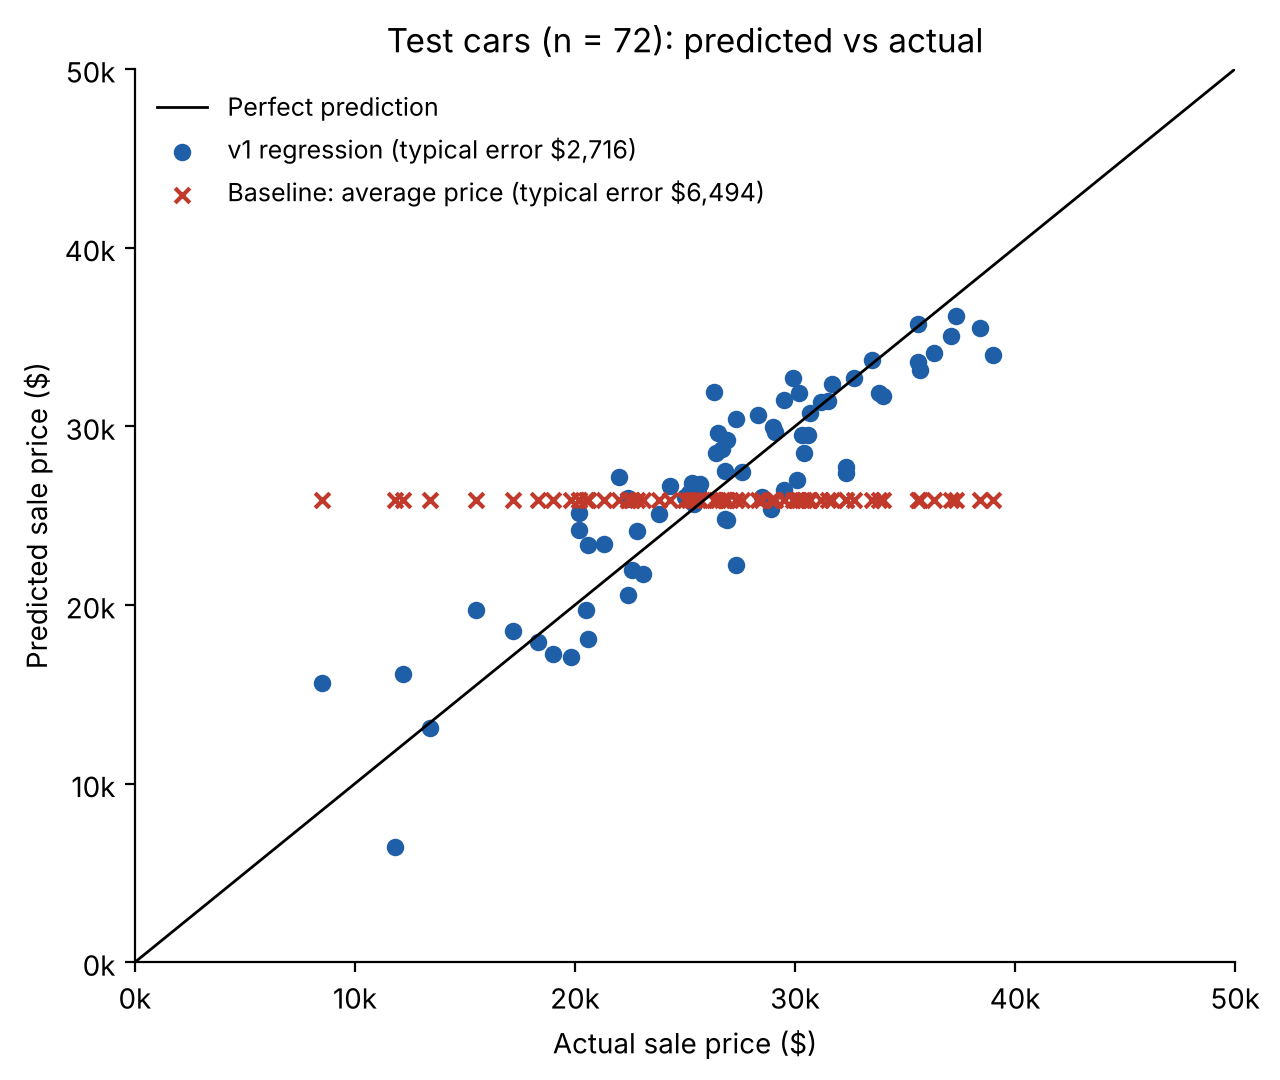

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
lo, hi = 0, 50000
ax.plot([lo, hi], [lo, hi], color="black", lw=1, label="Perfect prediction")
ax.scatter(y_test, pred_v1, s=28, color="#1f5fa8", label=f"v1 regression (typical error ${rmse(y_test, pred_v1):,.0f})")
ax.scatter(y_test, pred_base, s=28, color="#c0392b", marker="x",
           label=f"Baseline: average price (typical error ${rmse(y_test, pred_base):,.0f})")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("Actual sale price ($)")
ax.set_ylabel("Predicted sale price ($)")
ax.set_title(f"Test cars (n = {len(test)}): predicted vs actual")
fmt = plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figures/predicted_vs_actual.png", dpi=200)
plt.show()

## 4. Make the decision on the 40 auction lots

Rule: buy if auction price + $1,500 < predicted sale price, otherwise pass.
Profit on a bought car = later sale price − auction price − $1,500.

In [10]:
def v1_rule(car, auction_price, model=v1, prep_cost=PREP_COST):
    """Return 'buy' or 'pass' for one car.
    car: dict or Series with Mileage_K, Age_Years, Horsepower, Accident (1/0)"""
    predicted = model.predict(pd.DataFrame([car])).iloc[0]
    return "buy" if auction_price + prep_cost < predicted else "pass"

def baseline_rule(car, auction_price, avg_price=train_avg, prep_cost=PREP_COST):
    """Same rule, but every car is predicted to sell for the training average."""
    return "buy" if auction_price + prep_cost < avg_price else "pass"

# Example: one car
example = {"Mileage_K": 40, "Age_Years": 3, "Horsepower": 200, "Accident": 0}
print("Example car, $28,000 at auction ->", v1_rule(example, 28000))

Example car, $28,000 at auction -> buy


In [11]:
lots = auction.copy()
lots["Predicted_v1"] = v1.predict(lots).round(0)
lots["Profit_if_bought"] = lots["Later_Sale_Price"] - lots["Auction_Price"] - PREP_COST
lots["Baseline"] = [baseline_rule(r, r["Auction_Price"]) for _, r in lots.iterrows()]
lots["v1"] = [v1_rule(r, r["Auction_Price"]) for _, r in lots.iterrows()]

def summarize(decisions):
    bought = lots[decisions == "buy"]
    return {
        "Cars bought": len(bought),
        "Money-losing cars bought": int((bought["Profit_if_bought"] < 0).sum()),
        "Total profit ($)": int(bought["Profit_if_bought"].sum()),
        "Profit per car bought ($)": round(bought["Profit_if_bought"].mean()) if len(bought) else 0,
    }

decision_results = pd.DataFrame({
    "Baseline (average price)": summarize(lots["Baseline"]),
    "v1 regression": summarize(lots["v1"]),
}).T
decision_results

,Cars bought,Money-losing cars bought,Total profit ($),Profit per car bought ($)
Baseline (average price),14,10,-6000,-429
v1 regression,17,6,15800,929


In [12]:
# For reference: buying every lot, and the best possible (perfect hindsight)
print(f"Buy all 40:          profit ${lots['Profit_if_bought'].sum():,.0f}, "
      f"money-losers {(lots['Profit_if_bought'] < 0).sum()}")
best = lots[lots['Profit_if_bought'] > 0]
print(f"Perfect hindsight:   buys {len(best)}, profit ${best['Profit_if_bought'].sum():,.0f}")
diff = decision_results.loc['v1 regression', 'Total profit ($)'] - decision_results.loc['Baseline (average price)', 'Total profit ($)']
print(f"v1 minus baseline:   ${diff:,.0f} on this one auction")

Buy all 40:          profit $-35,500, money-losers 27
Perfect hindsight:   buys 12, profit $21,500
v1 minus baseline:   $21,800 on this one auction


In [13]:
# Lot-by-lot detail
lots[["Lot", "Mileage_K", "Age_Years", "Horsepower", "Accident", "Auction_Price",
      "Predicted_v1", "Later_Sale_Price", "Profit_if_bought", "Baseline", "v1"]]

,Lot,Mileage_K,Age_Years,Horsepower,Accident,Auction_Price,Predicted_v1,Later_Sale_Price,Profit_if_bought,Baseline,v1
0,1,71,6,120,0,21500,17466.0,19000,-4000,buy,pass
1,2,44,4,240,0,36100,31162.0,35600,-2000,pass,pass
2,3,76,6,235,0,26600,25703.0,28100,0,pass,pass
3,4,3,2,205,0,37800,34324.0,36700,-2600,pass,pass
4,5,77,5,215,0,23300,25416.0,24500,-300,buy,buy
5,6,35,3,120,0,28000,24155.0,28900,-600,pass,pass
6,7,51,7,175,0,24600,21864.0,22600,-3500,pass,pass
7,8,85,7,190,0,18300,20332.0,18600,-1200,buy,buy
8,9,18,3,175,0,29600,29609.0,28600,-2500,pass,pass
9,10,65,6,175,0,22400,22061.0,20500,-3400,buy,pass


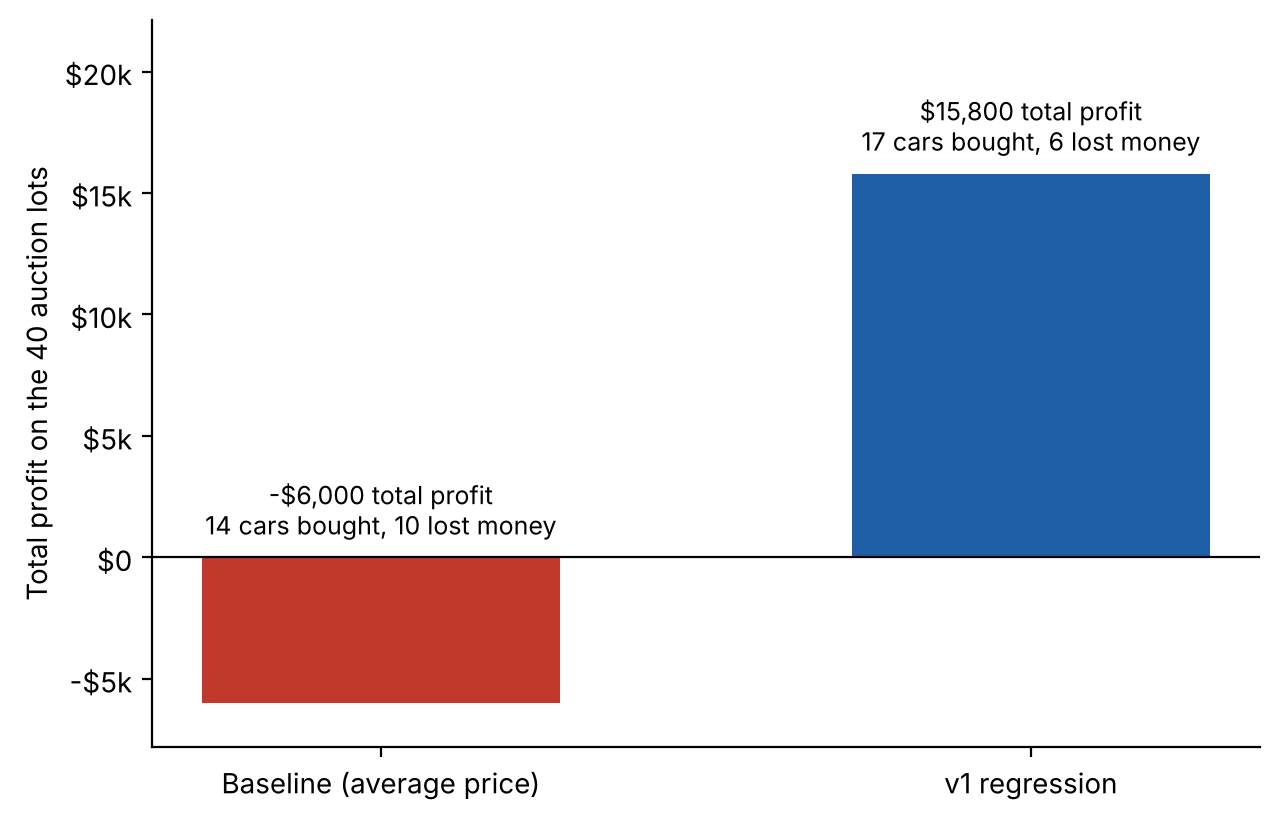

In [14]:
money = lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"
fig, ax = plt.subplots(figsize=(6.5, 4.2))
labels = decision_results.index
vals = decision_results["Total profit ($)"].values
bars = ax.bar(labels, vals, color=["#c0392b", "#1f5fa8"], width=0.55)
ax.axhline(0, color="black", lw=0.8)
for b, v, n, l in zip(bars, vals, decision_results["Cars bought"], decision_results["Money-losing cars bought"]):
    ax.text(b.get_x() + b.get_width()/2, max(v, 0) + 700,
            f"{money(v)} total profit\n{n} cars bought, {l} lost money", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Total profit on the 40 auction lots")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: money(x).replace(",000", "k")))
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(min(0, vals.min()) * 1.3, max(vals) * 1.4)
fig.tight_layout()
fig.savefig("figures/auction_profit.png", dpi=200)
plt.show()